C:\Users\laksh\AppData\Roaming\Python\Python313\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\laksh\AppData\Roaming\Python\Python313\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
C:\Users\laksh\AppData\Roaming\Python\Python313\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  


--- MODEL PERFORMANCE ---
Mean Absolute Error: 19.2
Root Mean Squared Error: 24.74
R2 Score: 0.9453

--- NEXT DAY PREDICTION ---
Latest available closing price: 1164.9
Predicted next closing price: 1159.35


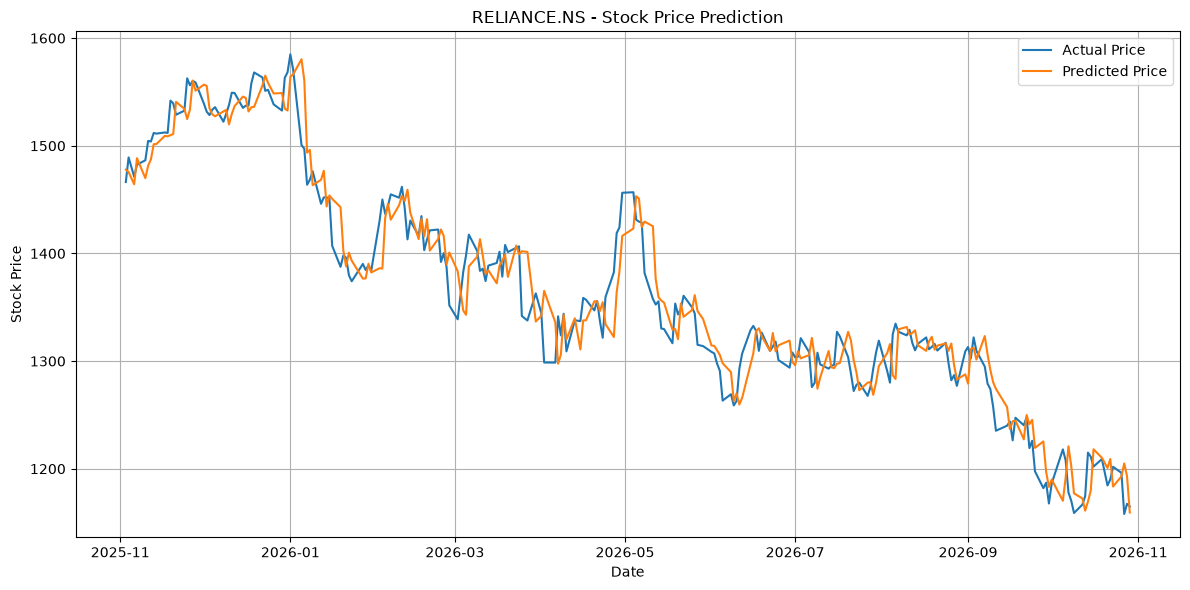

In [4]:

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Select stock
ticker = input("Enter stock ticker (e.g. RELIANCE.NS): ").strip()

# 2. Download historical data
data = yf.download(
    ticker,
    period="5y",
    interval="1d",
    auto_adjust=True,
    progress=False
)

if data.empty:
    raise ValueError("No stock data found. Check the ticker symbol.")

# Handle possible multi-level columns
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

# 3. Create prediction features
df = data[["Open", "High", "Low", "Close", "Volume"]].copy()

for lag in [1, 2, 3, 5, 10]:
    df[f"Close_Lag_{lag}"] = df["Close"].shift(lag)

df["MA_5"] = df["Close"].rolling(5).mean()
df["MA_10"] = df["Close"].rolling(10).mean()

df["Daily_Return"] = df["Close"].pct_change()
df["High_Low"] = (df["High"] - df["Low"]) / df["Close"]
df["Open_Close"] = (df["Close"] - df["Open"]) / df["Open"]

# 4. Target: next trading day's closing price
df["Target"] = df["Close"].shift(-1)

df = df.replace([np.inf, -np.inf], np.nan).dropna()

features = [
    "Close_Lag_1", "Close_Lag_2", "Close_Lag_3",
    "Close_Lag_5", "Close_Lag_10",
    "MA_5", "MA_10", "Daily_Return",
    "High_Low", "Open_Close", "Volume"
]

X = df[features]
y = df["Target"]

# 4. Prepare features and target separately
feature_data = df[features].replace(
    [np.inf, -np.inf], np.nan
)

target = df["Target"]

valid_data = feature_data.join(
    target.rename("Target")
).dropna()

X = valid_data[features]
y = valid_data["Target"]

# Keep the latest available day's features
latest_data = feature_data.dropna().iloc[[-1]]

# 5. Split data chronologically (no random shuffling)
split = int(len(df) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

# 6. Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# 7. Predict test prices
predictions = model.predict(X_test)

# 8. Evaluate model
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("\n--- MODEL PERFORMANCE ---")
print("Mean Absolute Error:", round(mae, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

# 9. Predict next trading day's closing price
latest_data = X.iloc[[-1]]
next_price = model.predict(latest_data)[0]

print("\n--- NEXT DAY PREDICTION ---")
print("Latest available closing price:",
      round(data["Close"].iloc[-1], 2))
print("Predicted next closing price:",
      round(next_price, 2))

# 10. Plot actual vs predicted prices
plt.figure(figsize=(12, 6))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual Price"
)

plt.plot(
    y_test.index,
    predictions,
    label="Predicted Price"
)

plt.title(f"{ticker} - Stock Price Prediction")
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
